# HW#5 -- Part I: Summarization using Encoder-Decoder Models

**Name:** Asad Khan
**Course:** CSC 583 -- Natural Language Processing, Fall 2026
**Assignment:** HW#5, Part I
**Collaborators:** None. GenAI disclosure: Claude (Anthropic) was used as a coding assistant.

## 0. Setup

The starter's setup cells assume Google Colab. I ran this notebook **locally** (Apple M4, PyTorch
`mps` backend) inside the course's uv environment, so the Drive mount and `pip install` lines are
kept below as comments and the working directory is simply this notebook's folder.

In [1]:
## Mount Google Drive (Colab only -- not needed when running locally)
# from google.colab import drive
# drive.mount("/content/drive")

In [2]:
# Change the working directory to this assignment's folder.
import os

# thisdir = "/content/drive/My Drive/CSC583_Fall2026/HW5"   # Colab
thisdir = os.getcwd()                                       # local: the HW5 folder
os.chdir(thisdir)
print(thisdir)

/Users/asadkhan/workspace/depaul/NLP/HW5


In [3]:
# Already installed in the local uv environment (see NLP/pyproject.toml)
# !pip install -q -U transformers tokenizers accelerate huggingface_hub datasets evaluate sentencepiece rouge_score bert_score

In [4]:
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"   # keep the baked-in outputs readable
import numpy as np
import pandas as pd
import torch

from datasets import load_dataset, get_dataset_config_names, disable_progress_bars
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM
from transformers.utils import logging as hf_logging
from evaluate import load as load_metric
import matplotlib.pyplot as plt
import transformers, datasets, evaluate

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
disable_progress_bars()
torch.manual_seed(42)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"    # Apple Silicon GPU
else:
    device = "cpu"
print("Using device:", device)
print("torch", torch.__version__, "| transformers", transformers.__version__,
      "| datasets", datasets.__version__, "| evaluate", evaluate.__version__)

Using device: mps
torch 2.14.0 | transformers 5.17.0 | datasets 5.0.1 | evaluate 0.4.6


## 1. Load the test set -- `RealTimeData/bbc_news_alltime`

Sample 300 random examples from the **most recent complete month** available on the HF hub.
Instead of hard-coding the month I list the dataset's configs and take the latest one.
Use the `'content'` column as the original text and `'description'` as the reference summary --
filter out any examples with no description first. I also drop articles whose `content` is empty
(the scraper sometimes failed on video/live pages), since there is nothing to summarize.

In [5]:
configs = get_dataset_config_names("RealTimeData/bbc_news_alltime")
print(f"{len(configs)} monthly configs, from {min(configs)} to {max(configs)}")

MONTH = max(configs)   # "YYYY-MM" strings sort chronologically
print("Using month:", MONTH)

full_month = load_dataset("RealTimeData/bbc_news_alltime", MONTH, split="train")
print("Articles in the month:", len(full_month))
dates = list(full_month["published_date"])
print("Publication dates:", min(dates), "to", max(dates))

news = full_month.filter(lambda ex: ex["description"] is not None and len(ex["description"]) > 0)
print("With a non-empty description:", len(news))
news = news.filter(lambda ex: ex["content"] is not None and len(ex["content"].split()) > 0)
print("... and a non-empty content:", len(news))

news = news.shuffle(seed=42).select(range(300))   # the randomly sampled test set
print("Test set:", news)

102 monthly configs, from 2017-01 to 2025-06
Using month: 2025-06


Articles in the month: 2671
Publication dates: 2025-06-01 to 2025-06-27
With a non-empty description: 2664
... and a non-empty content: 2661
Test set: Dataset({
    features: ['title', 'published_date', 'authors', 'description', 'section', 'content', 'link', 'top_image'],
    num_rows: 300
})


In [6]:
# A quick look at how long the inputs and the reference summaries are (in words)
content_len = [len(t.split()) for t in news["content"]]
desc_len = [len(t.split()) for t in news["description"]]
print(pd.DataFrame({"content words": content_len, "description words": desc_len}).describe().round(1))

       content words  description words
count          300.0              300.0
mean           574.9               18.1
std            417.7                4.8
min             10.0                6.0
25%            246.2               15.0
50%            564.0               18.0
75%            823.5               20.0
max           2147.0               39.0


## 2. Load the two models + tokenizers

Both `google-t5/t5-small` and `Falconsai/text_summarization` are encoder-decoder models --
load both through `AutoModelForSeq2SeqLM`. Remember: **you do NOT train either model** in
this part, only run inference.

In [7]:
MODEL_NAMES = {
    "t5-small (off-the-shelf)": "google-t5/t5-small",
    "Falconsai (fine-tuned)": "Falconsai/text_summarization",
}

tokenizers = {}
models = {}

for label, model_id in MODEL_NAMES.items():
    tokenizers[label] = AutoTokenizer.from_pretrained(model_id)
    models[label] = AutoModelForSeq2SeqLM.from_pretrained(model_id).to(device).eval()
    n_params = sum(p.numel() for p in models[label].parameters())
    print(f"{label:26s} {model_id:32s} {n_params/1e6:.1f}M parameters")

t5-small (off-the-shelf)   google-t5/t5-small               60.5M parameters


Falconsai (fine-tuned)     Falconsai/text_summarization     60.5M parameters


## 3. Preprocess / tokenize the test set

Following the assignment's hints: prefix each input with `"summarize: "`, tokenize with
`padding=True`, `truncation=True`, `max_length=1024`, then convert to PyTorch tensors with
`.set_format("torch")`. This is done **separately for each model's tokenizer**.

In [8]:
prefix = "summarize: "

def preprocess_function(examples, tokenizer):
    inputs = [prefix + doc for doc in examples["content"]]
    model_inputs = tokenizer(inputs, max_length=1024, padding=True, truncation=True)
    return model_inputs

tokenized = {}
for label, tok in tokenizers.items():
    # batch_size=len(news) so padding=True pads every example to one common length
    ds = news.map(lambda ex: preprocess_function(ex, tok), batched=True, batch_size=len(news),
                  remove_columns=news.column_names)
    ds.set_format("torch")
    tokenized[label] = ds
    print(f"{label:26s} input_ids shape: {tuple(ds[:]['input_ids'].shape)}")

# Are the two tokenizers actually the same? (Falconsai is a fine-tuned t5-small)
a, b = tokenized.values()
print("Identical token ids across the two tokenizers:", torch.equal(a[:]["input_ids"], b[:]["input_ids"]))
n_trunc = sum(len(tokenizers["t5-small (off-the-shelf)"](prefix + t)["input_ids"]) > 1024 for t in news["content"])
print(f"Articles truncated at 1024 tokens: {n_trunc} / {len(news)}")

t5-small (off-the-shelf)   input_ids shape: (300, 1024)


Falconsai (fine-tuned)     input_ids shape: (300, 1024)
Identical token ids across the two tokenizers: True


Articles truncated at 1024 tokens: 97 / 300


## 4. Run inference: generate summaries for the whole test set

Both models use the **same decoding settings**, so any difference in the outputs comes from the
weights, not from decoding: beam search with 4 beams, `no_repeat_ngram_size=3` (the value in
T5's own summarization config) and up to 128 new tokens. I first tried a 64-token cap, but many
summaries were then cut off mid-sentence, which would penalize both models for a decoding choice
rather than for what they learned.

In [9]:
from torch.utils.data import DataLoader

GEN_KWARGS = dict(max_new_tokens=128, num_beams=4, no_repeat_ngram_size=3, early_stopping=True)

def generate_summaries(model, tokenizer, tokenized_ds, batch_size=16, **gen_kwargs):
    loader = DataLoader(tokenized_ds, batch_size=batch_size)
    predictions = []
    with torch.no_grad():
        for batch in loader:
            out = model.generate(input_ids=batch["input_ids"].to(device),
                                 attention_mask=batch["attention_mask"].to(device),
                                 **gen_kwargs)
            predictions.extend(tokenizer.batch_decode(out, skip_special_tokens=True))
    return [p.strip() for p in predictions]

references = list(news["description"])
predictions = {}
for label in MODEL_NAMES:
    predictions[label] = generate_summaries(models[label], tokenizers[label], tokenized[label], **GEN_KWARGS)
    lens = [len(p.split()) for p in predictions[label]]
    n_cap = sum(len(tokenizers[label](p)["input_ids"]) >= GEN_KWARGS["max_new_tokens"] for p in predictions[label])
    print(f"{label:26s} {len(predictions[label])} summaries, mean length {np.mean(lens):.1f} words, "
          f"{n_cap} hit the {GEN_KWARGS['max_new_tokens']}-token cap")
print(f"{'reference':26s} mean length {np.mean([len(r.split()) for r in references]):.1f} words")

t5-small (off-the-shelf)   300 summaries, mean length 36.6 words, 0 hit the 128-token cap


Falconsai (fine-tuned)     300 summaries, mean length 40.9 words, 0 hit the 128-token cap
reference                  mean length 18.1 words


## 5. Metrics: ROUGE, Perplexity, BERTScore -- Requirement (*)

- **ROUGE** (`rouge1`, `rouge2`, plus `rougeL` for context): n-gram overlap with the reference.
- **Perplexity**: the `evaluate` "perplexity" metric is broken on current transformers versions
  (KNOWN ISSUE in the assignment), so I use the provided GPT-2 replacement function.
- **BERTScore** (precision, recall, F1): token-embedding similarity with the reference
  (default `roberta-large` scorer for `lang="en"`).

In [10]:
rouge = load_metric("rouge")
bertscore = load_metric("bertscore")

gpt2_tokenizer = AutoTokenizer.from_pretrained("gpt2")
gpt2_tokenizer.pad_token = gpt2_tokenizer.eos_token
gpt2_model = AutoModelForCausalLM.from_pretrained("gpt2").to(device)
gpt2_model.eval()

def per_text_perplexity(texts, max_length=1024):
    """GPT-2 perplexity of each text (NaN when it is too short for a next-token loss)."""
    perplexities = []
    with torch.no_grad():
        for text in texts:
            enc = gpt2_tokenizer(text, return_tensors="pt", truncation=True, max_length=max_length)
            input_ids = enc["input_ids"].to(device)
            if input_ids.size(1) < 2:
                perplexities.append(np.nan)   # too short to compute a next-token loss on
                continue
            loss = gpt2_model(input_ids, labels=input_ids).loss
            perplexities.append(torch.exp(loss).item())
    return perplexities

def compute_mean_perplexity(texts, max_length=1024):
    return float(np.nanmean(per_text_perplexity(texts, max_length)))   # this is 'mean_perplexity'

In [11]:
metric_results = {}
per_example = {}   # per-article scores, used for the distribution plot below

for label in MODEL_NAMES:
    preds = [p if p.strip() else "." for p in predictions[label]]   # guard against empty strings
    r = rouge.compute(predictions=preds, references=references)
    r_each = rouge.compute(predictions=preds, references=references, use_aggregator=False)
    ppl_each = per_text_perplexity(preds)
    bs = bertscore.compute(predictions=preds, references=references, lang="en")
    metric_results[label] = {
        "rouge1": r["rouge1"],
        "rouge2": r["rouge2"],
        "rougeL": r["rougeL"],
        "mean_perplexity": float(np.nanmean(ppl_each)),
        "median_perplexity": float(np.nanmedian(ppl_each)),
        "bertscore_precision": float(np.mean(bs["precision"])),
        "bertscore_recall": float(np.mean(bs["recall"])),
        "bertscore_f1": float(np.mean(bs["f1"])),
    }
    per_example[label] = pd.DataFrame({"rouge1": r_each["rouge1"], "rouge2": r_each["rouge2"],
                                       "perplexity": ppl_each, "bertscore_f1": bs["f1"]})

# Reference point: how fluent does GPT-2 find the human-written descriptions themselves?
ref_ppl_each = per_text_perplexity(references)
print(f"Perplexity of the reference descriptions: mean {np.nanmean(ref_ppl_each):.2f}, "
      f"median {np.nanmedian(ref_ppl_each):.2f}")

results_df = pd.DataFrame(metric_results).T
results_df.round(4)

Perplexity of the reference descriptions: mean 101.89, median 59.95


,rouge1,rouge2,rougeL,mean_perplexity,median_perplexity,bertscore_precision,bertscore_recall,bertscore_f1
t5-small (off-the-shelf),0.2702,0.1268,0.2221,71.5268,51.2103,0.8605,0.8849,0.8723
Falconsai (fine-tuned),0.2846,0.1372,0.2291,57.9164,42.0944,0.8622,0.8966,0.8788


In [12]:
# Paired comparison: on how many of the 300 articles does the fine-tuned model win?
base, ft = per_example["t5-small (off-the-shelf)"], per_example["Falconsai (fine-tuned)"]
for m in ["rouge1", "rouge2", "bertscore_f1"]:
    wins = (ft[m] > base[m]).sum(); ties = (ft[m] == base[m]).sum()
    print(f"{m:13s} Falconsai higher on {wins:3d}/300, tie on {ties:3d}, t5-small higher on {300 - wins - ties:3d}")

# How much does each model copy from the article? (share of summary 4-grams found verbatim in the source)
def copy_rate(summary, source, n=4):
    s = summary.lower().split(); src = source.lower().split()
    grams = {tuple(s[i:i+n]) for i in range(len(s) - n + 1)}
    if not grams:
        return np.nan
    src_grams = {tuple(src[i:i+n]) for i in range(len(src) - n + 1)}
    return len(grams & src_grams) / len(grams)

for label in MODEL_NAMES:
    rate = np.nanmean([copy_rate(p, c) for p, c in zip(predictions[label], news["content"])])
    print(f"{label:26s} 4-gram copy rate from the article: {rate:.1%}")
print(f"{'reference':26s} 4-gram copy rate from the article: "
      f"{np.nanmean([copy_rate(r, c) for r, c in zip(references, news['content'])]):.1%}")

rouge1        Falconsai higher on 145/300, tie on  22, t5-small higher on 133
rouge2        Falconsai higher on 134/300, tie on  60, t5-small higher on 106
bertscore_f1  Falconsai higher on 192/300, tie on   1, t5-small higher on 107


t5-small (off-the-shelf)   4-gram copy rate from the article: 61.3%
Falconsai (fine-tuned)     4-gram copy rate from the article: 69.5%
reference                  4-gram copy rate from the article: 24.4%


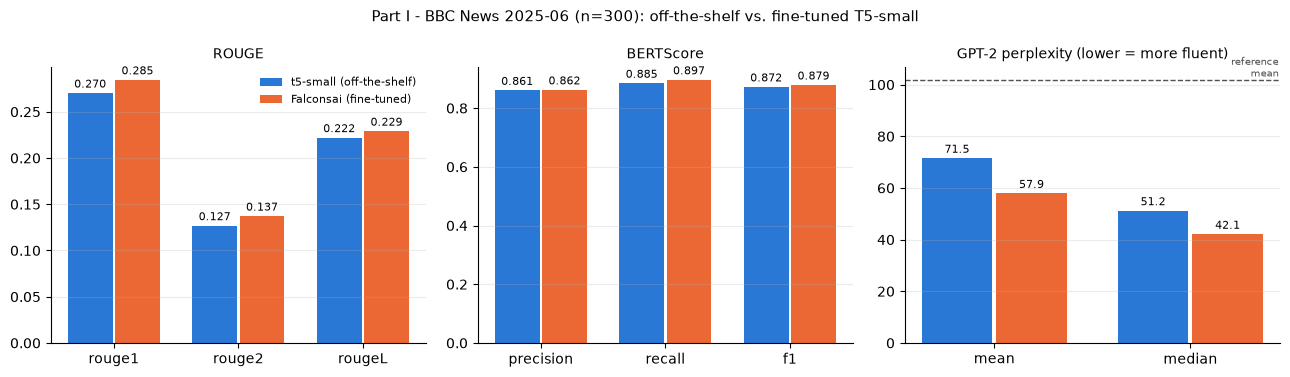

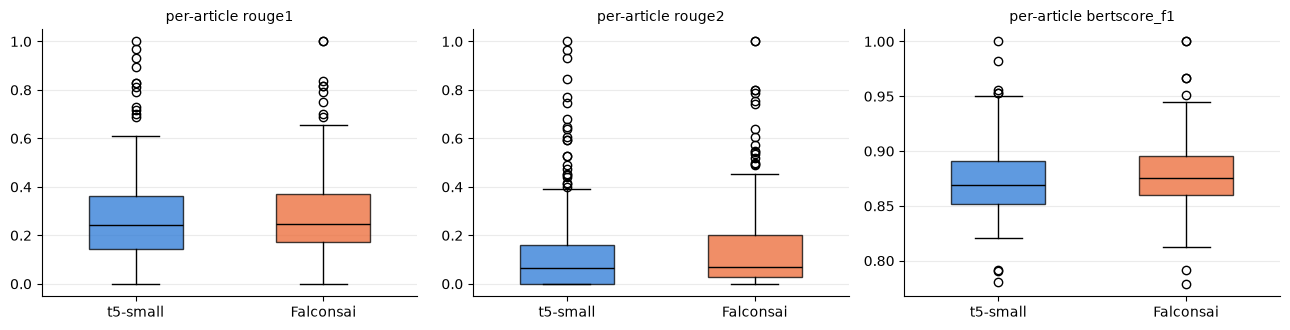

In [13]:
# Figures for the write-up
COLORS = {"t5-small (off-the-shelf)": "#2a78d6", "Falconsai (fine-tuned)": "#eb6834"}
labels = list(MODEL_NAMES)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
groups = [("ROUGE", ["rouge1", "rouge2", "rougeL"]),
          ("BERTScore", ["bertscore_precision", "bertscore_recall", "bertscore_f1"]),
          ("GPT-2 perplexity (lower = more fluent)", ["mean_perplexity", "median_perplexity"])]
for ax, (title, cols) in zip(axes, groups):
    x = np.arange(len(cols)); w = 0.38
    for i, lab in enumerate(labels):
        vals = [metric_results[lab][c] for c in cols]
        bars = ax.bar(x + (i - 0.5) * w, vals, w - 0.02, color=COLORS[lab], label=lab)
        ax.bar_label(bars, fmt="%.3f" if "perplexity" not in cols[0] else "%.1f", fontsize=8, padding=2)
    ax.set_xticks(x, [c.replace("bertscore_", "").replace("_perplexity", "") for c in cols])
    ax.set_title(title, fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
axes[2].axhline(np.nanmean(ref_ppl_each), color="#52514e", ls="--", lw=1)
axes[2].text(1.45, np.nanmean(ref_ppl_each), "reference\nmean", fontsize=7, va="bottom", ha="right", color="#52514e")
axes[0].legend(fontsize=8, frameon=False, loc="upper right")
fig.suptitle(f"Part I - BBC News {MONTH} (n=300): off-the-shelf vs. fine-tuned T5-small", fontsize=11)
fig.tight_layout()
fig.savefig("part1_metrics.png", dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, m in zip(axes, ["rouge1", "rouge2", "bertscore_f1"]):
    data = [per_example[lab][m] for lab in labels]
    bp = ax.boxplot(data, patch_artist=True, widths=0.5, medianprops=dict(color="black"))
    for patch, lab in zip(bp["boxes"], labels):
        patch.set_facecolor(COLORS[lab]); patch.set_alpha(0.75)
    ax.set_xticks([1, 2], ["t5-small", "Falconsai"])
    ax.set_title(f"per-article {m}", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig("part1_per_article.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Requirement (**): generate + compare summaries for two articles

I picked two articles from the test set with clearly different topics. Each is shown with a
preview of the article, the reference description and both models' summaries.

In [14]:
import textwrap

example_idx = [0, 7]

def show(title, text, width=110, limit=None):
    text = text if limit is None or len(text) <= limit else text[:limit] + " ..."
    print(f"{title}:\n" + textwrap.fill(text, width=width, initial_indent="    ", subsequent_indent="    ") + "\n")

for i in example_idx:
    print("=" * 112)
    print(f"Test-set index {i} | {news[i]['title']} | {news[i]['published_date']}")
    print("=" * 112)
    show("ARTICLE (first 900 characters)", news[i]["content"], limit=900)
    show("REFERENCE (description)", references[i])
    for label in MODEL_NAMES:
        s = per_example[label].iloc[i]
        show(f"{label}  [R1={s.rouge1:.3f}  R2={s.rouge2:.3f}  BERTScore-F1={s.bertscore_f1:.3f}]",
             predictions[label][i])

Test-set index 0 | Stress hormones: Why quick fixes won't lower our cortisol levels - BBC News | 2025-06-21
ARTICLE (first 900 characters):
    It could apparently change the shape of my face, add pounds to my midriff, and even make my hair fall out.
    I feel like warnings about cortisol - a stress hormone I know very little about - have hijacked my social
    media accounts. I see posts advising me to drink a cortisol cocktail - a blend of orange juice, coconut
    water and sea salt, take a range of different supplements, and massage lavender balm into my temples.  Not
    knowing how high my cortisol levels are makes it difficult to know whether or not I need to lower them,
    but, now I think about it, my cheeks do seem a touch more puffy than usual and my jeans have started to
    feel a bit tight.

REFERENCE (description):
    Can social media hacks really help bring down your cortisol levels?

t5-small (off-the-shelf)  [R1=0.086  R2=0.029  BERTScore-F1=0.847]:
    warnings ab

## 7. Save results (for the write-up)

In [15]:
results_df.round(4).to_csv("part1_metrics.csv")

rows = []
for i in example_idx:
    row = {"idx": i, "title": news[i]["title"], "content_preview": news[i]["content"][:900],
           "reference": references[i]}
    for label in MODEL_NAMES:
        row[label] = predictions[label][i]
    rows.append(row)
pd.DataFrame(rows).to_csv("part1_examples.csv", index=False)

all_preds = pd.DataFrame({"title": list(news["title"]), "reference": references,
                          **{label: predictions[label] for label in MODEL_NAMES}})
all_preds.to_csv("part1_all_predictions.csv", index=False)
print("Saved part1_metrics.csv, part1_examples.csv, part1_all_predictions.csv, part1_metrics.png, part1_per_article.png")

Saved part1_metrics.csv, part1_examples.csv, part1_all_predictions.csv, part1_metrics.png, part1_per_article.png
